# Ускоренные методы: тяжёлый шарик, Нестеров, рестарты

Градиентный спуск на сильно выпуклой задаче тратит $O(\kappa\log\frac1\varepsilon)$ итераций, и выбором длины шага это не лечится. Ускоренные методы меняют не длину шага, а направление: к антиградиенту добавляется инерция, и оценка улучшается до $O(\sqrt{\kappa}\log\frac1\varepsilon)$. За это приходится платить: методы перестают быть монотонными, а их параметры зависят от констант $L$ и $\mu$, которых мы обычно не знаем.

Семинар выстроен вокруг этой платы. Сначала — два ускоренных метода и цена обусловленности на квадратичных задачах, где всё считается точно. Затем сопряжённые градиенты как метод, которому параметры не нужны вовсе. Со второй половины переходим к логистической регрессии и на ней разбираем рестарты — приём, который возвращает ускорение без знания $\mu$, — и оценку $\mu$ прямо по ходу работы.

In [ ]:
import time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams.update({
    "figure.figsize": (12, 5), "legend.fontsize": 11, "axes.labelsize": 13,
    "axes.titlesize": 13, "xtick.labelsize": 11, "ytick.labelsize": 11,
    "lines.linewidth": 1.8,
})
np.set_printoptions(precision=4, suppress=True)

## 1. Инфраструктура

Все методы наследуют один интерфейс: `solve(x0, f, gradf, tol, max_iter)` и список `history` с точками траектории. Отдельно считаем вызовы оракула — для методов с линейным поиском число итераций и число вызовов $f$ расходятся на порядок.

In [ ]:
class Oracle:
    '''Обёртка, считающая вызовы f и grad f.'''
    def __init__(self, f, gradf):
        self._f, self._g = f, gradf
        self.nf = self.ng = 0
    def f(self, x):
        self.nf += 1; return self._f(x)
    def gradf(self, x):
        self.ng += 1; return self._g(x)


class Method:
    def __init__(self, name=None):
        self.name = name; self.history = []
    def _log(self, x):
        self.history.append((x.copy(), time.time()))


class GradientDescent(Method):
    def __init__(self, alpha, name=None):
        super().__init__(name); self.alpha = alpha
    def solve(self, x0, f, gradf, tol=1e-8, max_iter=10000):
        x = x0.copy(); self.history = [(x.copy(), time.time())]
        for k in range(max_iter):
            g = gradf(x)
            if np.linalg.norm(g) <= tol:
                break
            x = x - self.alpha * g
            self._log(x)
        return x


def iters(m):
    return len(m.history) - 1

## 2. Метод тяжёлого шарика

$$x_{k+1} = x_k - \alpha\,\nabla f(x_k) + \beta\,(x_k - x_{k-1}).$$

Второе слагаемое — инерция: шаг помнит, куда метод двигался раньше. Для квадратичной функции это гасит зигзаг градиентного спуска между стенками узкого оврага.

Для $\mu$-сильно выпуклой функции с $L$-липшицевым градиентом оптимальные параметры
$$\alpha = \frac{4}{(\sqrt{L}+\sqrt{\mu})^2}, \qquad \beta = \left(\frac{\sqrt{\kappa}-1}{\sqrt{\kappa}+1}\right)^2$$
дают оценку
$$\left\|\begin{bmatrix} x_{k+1}-x^*\\ x_k - x^*\end{bmatrix}\right\|_2 \le \left(\frac{\sqrt{\kappa}-1}{\sqrt{\kappa}+1}\right)^{k}\left\|\begin{bmatrix} x_{1}-x^*\\ x_0 - x^*\end{bmatrix}\right\|_2 .$$

Показатель $1 - 1/\sqrt{\kappa}$ вместо $1 - 1/\kappa$ у градиентного спуска — это и есть ускорение. Важная оговорка: для квадратичных задач оценка верна, но на общих сильно выпуклых функциях метод тяжёлого шарика с этими параметрами может не сходиться (контрпример Лессара, Рекхта и Пакарда, 2016).

In [ ]:
class HeavyBall(Method):
    def __init__(self, alpha=None, beta=None, L=None, mu=None, name=None):
        super().__init__(name)
        if alpha is None:
            alpha = 4 / (np.sqrt(L) + np.sqrt(mu))**2
            beta = max((1 - np.sqrt(alpha*L))**2, (1 - np.sqrt(alpha*mu))**2)
        self.alpha, self.beta = alpha, beta
    def solve(self, x0, f, gradf, tol=1e-8, max_iter=10000):
        x = x0.copy(); xp = x0.copy(); self.history = [(x.copy(), time.time())]
        for k in range(max_iter):
            g = gradf(x)
            if np.linalg.norm(g) <= tol:
                break
            xp, x = x, x - self.alpha * g + self.beta * (x - xp)
            self._log(x)
        return x

## 3. Ускоренный метод Нестерова

Отличие от тяжёлого шарика в одном: градиент вычисляется не в текущей точке, а в сдвинутой по инерции.

$$y_0 = x_0, \qquad x_{k+1} = y_k - \alpha\,\nabla f(y_k), \qquad y_{k+1} = x_{k+1} + \beta_k\,(x_{k+1} - x_k).$$

Форм записи две, и выбор между ними — главный сюжет семинара.

**Выпуклая форма**: $\beta_k = \dfrac{k}{k+3}$, никаких констант знать не нужно. Для выпуклой $f$ с $L$-липшицевым градиентом и $\alpha = 1/L$
$$f(x_k) - f^* \le \frac{2L\|x_0-x^*\|^2}{(k+1)^2}.$$

**Сильно выпуклая форма**: $\beta = \dfrac{\sqrt{L}-\sqrt{\mu}}{\sqrt{L}+\sqrt{\mu}}$ — постоянный коэффициент, зависящий от $\mu$. Тогда
$$f(x_k) - f^* \le L\Bigl(1 - \tfrac{1}{\sqrt{\kappa}}\Bigr)^{k}\|x_0 - x^*\|^2 .$$

Вторая оценка линейная, первая — только степенная. Но вторая требует $\mu$, а первая нет.

In [ ]:
class Nesterov(Method):
    # Запись в обозначениях статьи про NAG-free:
    #   y_{t+1} = x_t - grad f(x_t) / L         (шаг по градиенту)
    #   x_{t+1} = y_{t+1} + beta_t (y_{t+1} - y_t)   (экстраполяция)
    # За итерацию вычисляется ровно один градиент - в точке x_t.
    # mode:    "conv" (beta_t = k/(k+3)) или "sc" (постоянная beta по mu)
    # restart: None | "func" | "grad" | "fixed" (с периодом period)
    def __init__(self, L, mode="conv", mu=None, restart=None, period=None, name=None):
        super().__init__(name)
        self.L, self.mode, self.mu = L, mode, mu
        self.restart, self.period = restart, period
        self.restarts = []
    def solve(self, x0, f, gradf, tol=1e-8, max_iter=10000):
        L = self.L
        x = x0.copy(); y = x0.copy()
        self.history = [(x.copy(), time.time())]; self.restarts = []; k = 0
        g = gradf(x); gn = np.linalg.norm(g)
        f_y = f(y) if self.restart == "func" else None
        beta_sc = (None if self.mode == "conv" else
                   (np.sqrt(L) - np.sqrt(self.mu)) / (np.sqrt(L) + np.sqrt(self.mu)))
        for t in range(max_iter):
            if gn <= tol:
                break
            y_new = x - g / L
            beta = beta_sc if self.mode == "sc" else k / (k + 3)
            x_new = y_new + beta * (y_new - y)
            g_new = gradf(x_new); gn_new = np.linalg.norm(g_new)
            f_y_new = f(y_new) if self.restart == "func" else None
            need = ((self.restart == "func"  and f_y_new > f_y) or
                    (self.restart == "grad"  and gn_new > gn) or
                    (self.restart == "fixed" and (t + 1) % self.period == 0))
            if need:
                self.restarts.append(t + 1)
            k = 0 if need else k + 1
            x, y, g, gn, f_y = x_new, y_new, g_new, gn_new, f_y_new
            self.history.append((y.copy(), time.time()))
        return y

### 3.1. Как выглядят траектории

Двумерная задача $f(x) = \tfrac12(x_1^2 + \gamma x_2^2)$ с $\gamma = 20$: вытянутая чаша, в которой градиентный спуск с оптимальным шагом $2/(L+\mu)$ вынужден зигзагообразно биться между стенками.

GD, $2/(L+\mu)$               216 итераций
тяжёлый шарик                  58 итераций
Нестеров, известное $\mu$      94 итераций


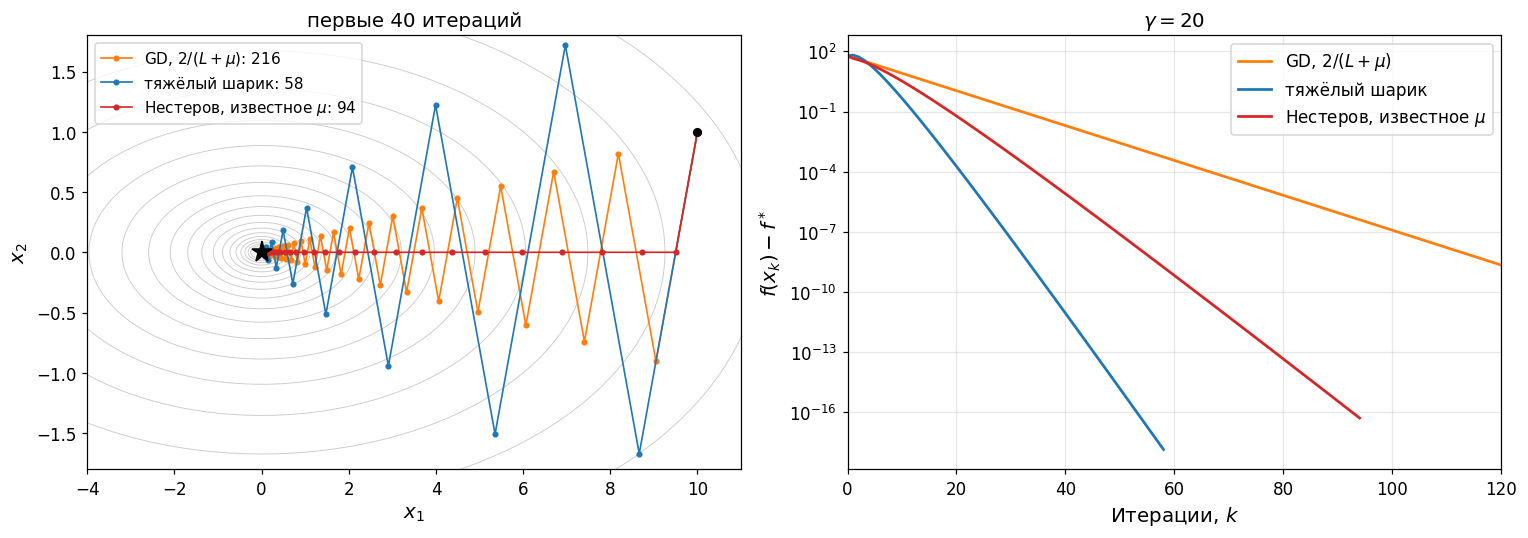

In [ ]:
gam = 20.0
A2 = np.diag([1.0, gam])
f2 = lambda x: 0.5 * x @ A2 @ x
g2 = lambda x: A2 @ x
L2, mu2 = gam, 1.0
x02 = np.array([10.0, 1.0])

ms2 = [GradientDescent(2 / (L2 + mu2),   name=r"GD, $2/(L+\mu)$"),
       HeavyBall(L=L2, mu=mu2,           name="тяжёлый шарик"),
       Nesterov(L2, "sc", mu=mu2,        name=r"Нестеров, известное $\mu$")]
for m in ms2:
    m.solve(x02, f2, g2, tol=1e-8, max_iter=3000)
    print(f"{m.name:28s} {iters(m):4d} итераций")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
gx = np.linspace(-4, 11, 500); gy = np.linspace(-1.8, 1.8, 500)
GX, GY = np.meshgrid(gx, gy); Z = 0.5 * (GX**2 + gam * GY**2)
axes[0].contour(GX, GY, Z, levels=np.logspace(-1.5, 2, 20), colors="0.8", linewidths=.6)
for m, c in zip(ms2, ["C1", "C0", "C3"]):
    xy = np.array([p for p, _ in m.history])[:40]
    axes[0].plot(xy[:, 0], xy[:, 1], "o-", color=c, ms=3, lw=1.1,
                 label=f"{m.name}: {iters(m)}")
axes[0].plot(0, 0, "k*", ms=14); axes[0].plot(*x02, "ko", ms=5)
axes[0].set_xlim(-4, 11); axes[0].set_ylim(-1.8, 1.8)
axes[0].set_xlabel("$x_1$"); axes[0].set_ylabel("$x_2$")
axes[0].set_title("первые 40 итераций"); axes[0].legend(fontsize=10, loc="upper left")

for m, c in zip(ms2, ["C1", "C0", "C3"]):
    axes[1].semilogy([f2(p) + 1e-20 for p, _ in m.history], color=c, label=m.name)
axes[1].set_xlim(0, 120); axes[1].set_xlabel("Итерации, $k$")
axes[1].set_ylabel("$f(x_k) - f^*$"); axes[1].set_title(f"$\\gamma = {gam:.0f}$")
axes[1].grid(alpha=.3); axes[1].legend()
plt.tight_layout(); plt.show()

Градиентный спуск делает много мелких шагов поперёк оврага. Тяжёлый шарик тоже колеблется, но реже и размашистее: инерция переносит его вдоль дна, и до решения он добирается вчетверо быстрее. Траектория метода Нестерова почти прямая — градиент в сдвинутой точке уже «смотрит» туда, куда метод летит, и поперечная составляющая гасится заранее.

Обратите внимание: ни один из ускоренных методов не монотонен по расстоянию до решения. Это не дефект реализации, а свойство методов. К нему мы вернёмся в части про рестарты.

## 4. Цена обусловленности: $\kappa$ против $\sqrt{\kappa}$

Измерим зависимость числа итераций от $\kappa$ напрямую. Квадратичная задача размерности $50$ с логарифмически распределённым спектром от $1$ до $\kappa$.

kappa =   1e+01:  GD     143  HB     33  Нестеров(mu)     46  Нестеров(вып.)    175  +рестарт     67
kappa =   1e+02:  GD    1292  HB    115  Нестеров(mu)    149  Нестеров(вып.)   1136  +рестарт    322
kappa =   1e+03:  GD   10831  HB    385  Нестеров(mu)    422  Нестеров(вып.)   5383  +рестарт    832
kappa =   1e+04:  GD   86501  HB   1285  Нестеров(mu)   1149  Нестеров(вып.)  19226  +рестарт   1483
kappa =   1e+05:  GD  644345  HB   4266  Нестеров(mu)   3178  Нестеров(вып.)  37935  +рестарт   5241


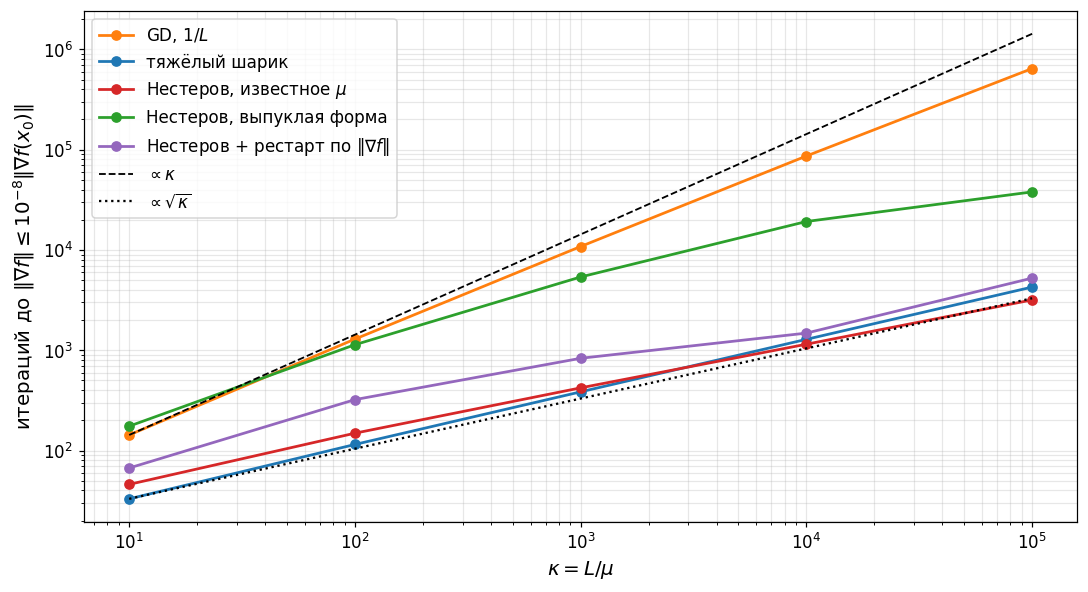

In [ ]:
rng = np.random.default_rng(0)
n_sweep = 50
Q, _ = np.linalg.qr(rng.standard_normal((n_sweep, n_sweep)))

kappas, rows = [], []
for e in range(1, 6):
    kap = 10.0**e
    d = np.logspace(0, e, n_sweep)
    A = Q @ np.diag(d) @ Q.T; A = (A + A.T) / 2
    fq = lambda x, A=A: 0.5 * x @ A @ x
    gq = lambda x, A=A: A @ x
    x0 = Q @ np.ones(n_sweep)
    L, mu = d.max(), d.min()
    tol = 1e-8 * np.linalg.norm(gq(x0))
    row = []
    for m in [GradientDescent(1 / L), HeavyBall(L=L, mu=mu), Nesterov(L, "sc", mu=mu),
              Nesterov(L), Nesterov(L, restart="grad")]:
        m.solve(x0, fq, gq, tol=tol, max_iter=1000000)
        row.append(iters(m))
    kappas.append(kap); rows.append(row)
    print(f"kappa = {kap:7.0e}:  GD {row[0]:7d}  HB {row[1]:6d}  Нестеров(mu) {row[2]:6d}  "
          f"Нестеров(вып.) {row[3]:6d}  +рестарт {row[4]:6d}")

rows = np.array(rows); kappas = np.array(kappas)
names = ["GD, $1/L$", "тяжёлый шарик", r"Нестеров, известное $\mu$",
         "Нестеров, выпуклая форма", r"Нестеров + рестарт по $\|\nabla f\|$"]
fig, ax = plt.subplots(figsize=(10, 5.5))
for j, (nm, c) in enumerate(zip(names, ["C1", "C0", "C3", "C2", "C4"])):
    ax.loglog(kappas, rows[:, j], "o-", color=c, label=nm)
ax.loglog(kappas, rows[0, 0] / kappas[0] * kappas, "k--", lw=1.2, label=r"$\propto \kappa$")
ax.loglog(kappas, rows[0, 1] / np.sqrt(kappas[0]) * np.sqrt(kappas), "k:", lw=1.5,
          label=r"$\propto \sqrt{\kappa}$")
ax.set_xlabel(r"$\kappa = L/\mu$"); ax.set_ylabel(r"итераций до $\|\nabla f\| \leq 10^{-8}\|\nabla f(x_0)\|$")
ax.grid(alpha=.3, which="both"); ax.legend()
plt.tight_layout(); plt.show()

Три линии ложатся на $\sqrt{\kappa}$: тяжёлый шарик, Нестеров с известным $\mu$ и Нестеров с рестартом. Градиентный спуск идёт параллельно $\kappa$ — при $\kappa = 10^5$ это разница в полтора порядка по числу итераций.

Отдельная строка — Нестеров в выпуклой форме без рестарта. Он не знает $\mu$, не пользуется сильной выпуклостью и потому растёт быстрее $\sqrt{\kappa}$: оценка $O(1/k^2)$ не линейная. Разрыв между этой кривой и кривой с известным $\mu$ предстоит закрыть рестартом.

---
# Часть II. Сопряжённые градиенты

## 5. Квадратичный случай

Для $f(x) = \tfrac12 x^\top A x - b^\top x$ с $A \in \mathbb{S}^n_{++}$ условие минимума — это система $Ax = b$, а градиент $\nabla f(x_k) = Ax_k - b = r_k$ есть невязка этой системы.

Векторы $\{p_0,\dots,p_l\}$ называются **сопряжёнными** относительно $A$, если $p_i^\top A p_j = 0$ при $i \ne j$. Двигаясь по сопряжённым направлениям с точной минимизацией вдоль каждого, мы за $n$ шагов приходим к решению: в базисе из сопряжённых векторов задача распадается на $n$ независимых одномерных.

Метод сопряжённых градиентов строит такие направления на ходу: $p_k = -r_k + \beta_k p_{k-1}$, где $\beta_k$ выбирается из условия $p_k^\top A p_{k-1} = 0$. Пользуясь ортогональностями $r_k^\top r_i = 0$ и $p_k^\top A p_i = 0$ для $i < k$, формулы упрощаются до
$$\alpha_k = \frac{r_k^\top r_k}{p_k^\top A p_k}, \qquad \beta_k = \frac{r_k^\top r_k}{r_{k-1}^\top r_{k-1}}.$$
Хранить нужно четыре вектора, самая дорогая операция на итерации — одно умножение $Ap_k$.

**Теорема.** $\|x_k - x^*\|_A \le \left(\dfrac{\sqrt{\kappa}-1}{\sqrt{\kappa}+1}\right)^k \|x_0 - x^*\|_A$.

Оценка та же, что у ускоренных методов, но получена она без знания $L$ и $\mu$: в методе нет ни одного параметра, который нужно задавать.

In [ ]:
class CGQuadratic(Method):
    def __init__(self, A, name=None):
        super().__init__(name); self.A = A
    def solve(self, x0, f, gradf, tol=1e-8, max_iter=10000):
        A = self.A
        x = x0.copy(); self.history = [(x.copy(), time.time())]
        r = gradf(x); p = -r
        for k in range(max_iter):
            if np.linalg.norm(r) <= tol:
                break
            Ap = A @ p
            alpha = r @ r / (p @ Ap)
            x = x + alpha * p
            r_new = r + alpha * Ap
            p = -r_new + (r_new @ r_new) / (r @ r) * p
            r = r_new
            self._log(x)
        return x

### 5.1. Эксперимент

Квадратичная задача размерности $100$ с собственными значениями от $1$ до $10^4$, то есть $\kappa = 10^4$.

n = 100,  kappa = 10000
GD, $1/L$                     37577 итераций
тяжёлый шарик                  1043 итераций
Нестеров, известное $\mu$       710 итераций
CG                              181 итераций


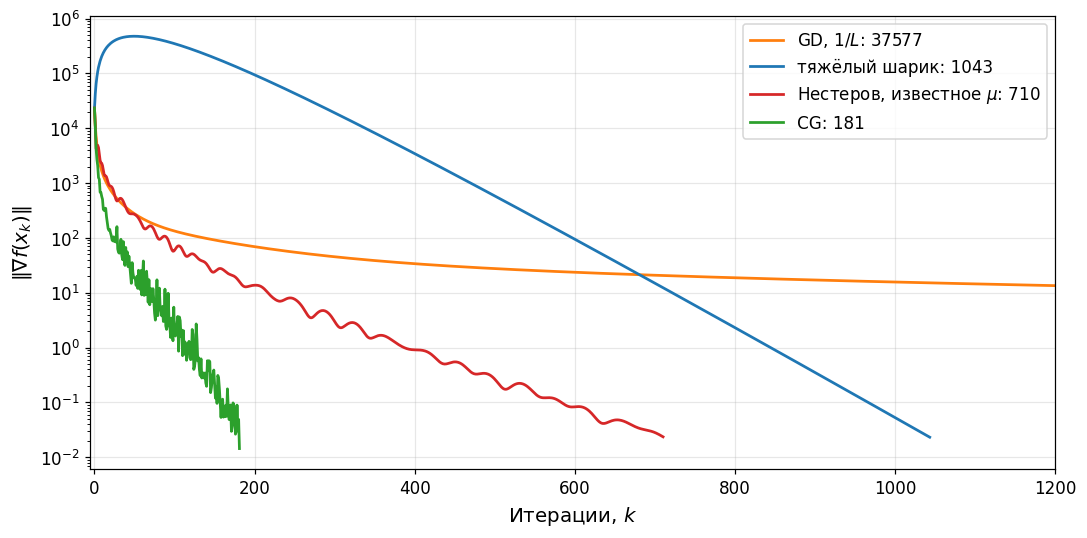

In [ ]:
rng = np.random.default_rng(1)
n_cg = 100
d_cg = np.logspace(0, 4, n_cg)
Qc, _ = np.linalg.qr(rng.standard_normal((n_cg, n_cg)))
Acg = Qc @ np.diag(d_cg) @ Qc.T; Acg = (Acg + Acg.T) / 2
x_cg = rng.standard_normal(n_cg); bcg = Acg @ x_cg
fcg = lambda x: 0.5 * x @ Acg @ x - bcg @ x
gcg = lambda x: Acg @ x - bcg
Lc, muc = d_cg.max(), d_cg.min()
x0c = np.zeros(n_cg)
tol_c = 1e-6 * np.linalg.norm(gcg(x0c))
print(f"n = {n_cg},  kappa = {Lc/muc:.0f}")

ms_cg = [GradientDescent(1 / Lc,        name="GD, $1/L$"),
         HeavyBall(L=Lc, mu=muc,        name="тяжёлый шарик"),
         Nesterov(Lc, "sc", mu=muc,     name=r"Нестеров, известное $\mu$"),
         CGQuadratic(Acg,               name="CG")]
for m in ms_cg:
    m.solve(x0c, fcg, gcg, tol=tol_c, max_iter=200000)
    print(f"{m.name:28s} {iters(m):6d} итераций")

fig, ax = plt.subplots(figsize=(10, 5))
for m, c in zip(ms_cg, ["C1", "C0", "C3", "C2"]):
    ax.semilogy([np.linalg.norm(gcg(p)) + 1e-18 for p, _ in m.history],
                color=c, label=f"{m.name}: {iters(m)}")
ax.set_xlim(-5, 1200); ax.set_xlabel("Итерации, $k$"); ax.set_ylabel(r"$\|\nabla f(x_k)\|$")
ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

Сто восемьдесят итераций против семисот у лучшего из ускоренных методов и тридцати семи тысяч у градиентного спуска. При этом сопряжённым градиентам не нужно знать ни $L$, ни $\mu$: длина шага считается аналитически.

Заодно на графике хорошо видна немонотонность: норма градиента у тяжёлого шарика сначала вырастает на два порядка и только потом начинает убывать, а у сопряжённых градиентов колеблется на всём протяжении. Убывает в обоих случаях не норма градиента, а другая величина — у CG это $\|x_k - x^*\|_A$.

Про конечность стоит сделать оговорку. Теория обещает сходимость не более чем за $n = 100$ шагов, но это в точной арифметике. В двойной точности при $\kappa = 10^4$ ортогональность невязок постепенно теряется, и фактически понадобилось около $2n$ итераций. На порядок величины это не влияет, но помнить об этом стоит: конечность метода — свойство арифметики, а не только алгоритма.

## 6. Нелинейный случай

Для неквадратичной функции невязки $r_k$ заменяются градиентами, а аналитический шаг — линейным поиском по условиям Вольфа. Остаётся выбрать $\beta_k$; две классические формулы совпадают на квадратичной задаче и расходятся на остальных:

$$\beta_k^{\mathrm{FR}} = \frac{\|\nabla f(x_k)\|^2}{\|\nabla f(x_{k-1})\|^2} \quad \text{(Флетчер — Ривс)},
\qquad
\beta_k^{\mathrm{PR}} = \frac{\langle \nabla f(x_k) - \nabla f(x_{k-1}),\, \nabla f(x_k)\rangle}{\|\nabla f(x_{k-1})\|^2} \quad \text{(Полак — Рибьер)}.$$

Здесь впервые появляется рестарт — и по той же причине, по которой он понадобится в ускоренных методах. Накопленное направление $p_k$ со временем перестаёт быть направлением убывания; сброс $p_k = -\nabla f(x_k)$ начинает построение заново. Для метода Флетчера — Ривса без рестартов известны примеры крайне медленной сходимости (Nocedal, Wright, Ch. 5). Стандартные правила сброса: каждые $n$ итераций, при $\langle \nabla f(x_k), \nabla f(x_{k-1})\rangle / \|\nabla f(x_k)\|^2 \ge \nu \approx 0.1$ или при потере направления убывания $\langle p_k, \nabla f(x_k)\rangle \ge 0$. Последнее правило встроено в реализацию ниже.

In [ ]:
class Wolfe:
    def __init__(self, beta1=1e-4, beta2=0.9, alpha0=1.0, max_it=60):
        self.b1, self.b2, self.a0, self.max_it = beta1, beta2, alpha0, max_it
    def __call__(self, x, p, f, gradf):
        lb, ub, a = 0.0, np.inf, self.a0
        fx = f(x); pg = p @ gradf(x)
        for _ in range(self.max_it):
            xn = x + a * p
            if f(xn) > fx + self.b1 * a * pg:
                ub = a; a = 0.5 * (lb + ub)
            elif gradf(xn) @ p < self.b2 * pg:
                lb = a; a = 2 * lb if np.isinf(ub) else 0.5 * (lb + ub)
            else:
                return a
            if ub - lb <= 1e-14:
                break
        return a


class NonlinearCG(Method):
    '''rule in {"FR", "PR"}; restart — период сброса или None.'''
    def __init__(self, rule="PR", line_search=None, restart=None, name=None):
        super().__init__(name)
        self.rule = rule; self.ls = line_search or Wolfe(); self.restart = restart
    def solve(self, x0, f, gradf, tol=1e-8, max_iter=10000):
        x = x0.copy(); self.history = [(x.copy(), time.time())]
        g = gradf(x); p = -g
        for k in range(max_iter):
            if np.linalg.norm(g) <= tol:
                break
            a = self.ls(x, p, f, gradf)
            if a < 1e-18:
                break
            x = x + a * p
            g_new = gradf(x)
            if self.rule == "FR":
                beta = (g_new @ g_new) / (g @ g)
            else:
                beta = max(0.0, (g_new @ (g_new - g)) / (g @ g))
            p = -g_new + beta * p; g = g_new
            if (self.restart and (k + 1) % self.restart == 0) or p @ g >= 0:
                p = -g
            self._log(x)
        return x

---
# Часть III. Рестарты в ускоренном методе

## 7. Откуда берутся колебания

В выпуклой форме коэффициент инерции $\beta_k = k/(k+3)$ растёт к единице и больше никогда не уменьшается. Если задача на самом деле сильно выпукла, правильным был бы постоянный коэффициент $\beta = \frac{\sqrt{\kappa}-1}{\sqrt{\kappa}+1} < 1$. Метод его проскакивает: инерция становится слишком большой, точка проносится мимо минимума, разворачивается, проносится снова. На графике значения функции это видно как затухающие волны.

Лечение — сбросить счётчик: положить $k = 0$ и $y = x$. Инерция обнуляется, и метод начинает разгон заново с текущей точки. Вопрос только в том, когда сбрасывать.

**Фиксированный период.** Сброс каждые $K$ итераций. Оптимальное $K$ имеет порядок $\sqrt{\kappa}$ — то есть требует ровно того знания, от которого мы хотели избавиться.

**По функции.** Сброс при $f(x_{k+1}) > f(x_k)$: метод пошёл вверх, значит, разгон уже вреден.

**По норме градиента.** Сброс при $\|\nabla f(x_{k+1})\| > \|\nabla f(x_k)\|$. Отличие от предыдущего правила в том, что не нужно вычислять $f$: градиент и так считается на каждой итерации.

Оба адаптивных правила не содержат ни одной константы, которую надо подбирать под задачу. Теоретическое обоснование даёт работа O'Donoghue, Candès (2015), где анализируется близкий вариант с условием $\langle \nabla f(y_k),\, x_{k+1} - x_k\rangle > 0$.

## 8. Сквозной пример: логистическая регрессия

Дальше до конца семинара работаем с одной задачей:
$$f(w) = \frac1m\sum_{i=1}^m \log\bigl(1 + e^{-y_i a_i^\top w}\bigr) + \frac{\lambda}{2}\|w\|_2^2 .$$

Она сильно выпукла с $\mu \ge \lambda$ и имеет липшицев градиент с $L \le \lambda + \sigma_{\max}^2(A)/(4m)$, то есть обе константы формально известны. Но оценка $\mu = \lambda$ — это оценка снизу, и обычно сильно заниженная: вблизи решения кривизна складывается из $\lambda$ и вклада данных. Возьмём $\lambda = 10^{-8}$ и плохо обусловленную матрицу признаков, чтобы разрыв между гарантированной и настоящей кривизной был большим.

In [ ]:
rng = np.random.default_rng(0)
m_lr, n_lr = 500, 200
U, _ = np.linalg.qr(rng.standard_normal((m_lr, n_lr)))
V, _ = np.linalg.qr(rng.standard_normal((n_lr, n_lr)))
Adat = U @ np.diag(np.logspace(0, -1, n_lr)) @ V.T       # сингулярные числа от 1 до 0.1
w_gen = rng.standard_normal(n_lr)
y_lab = np.sign(Adat @ w_gen)
y_lab[rng.random(m_lr) < 0.3] *= -1                      # 30% шума в метках
lam = 1e-8
Ay = Adat * y_lab[:, None]

f_lr = lambda w: np.mean(np.logaddexp(0, -(Ay @ w))) + lam / 2 * w @ w
def g_lr(w):
    z = Ay @ w
    return Ay.T @ (-1 / (1 + np.exp(z))) / m_lr + lam * w

w0 = np.zeros(n_lr)
L_lr = lam + np.linalg.norm(Adat, 2)**2 / (4 * m_lr)
tol_lr = 1e-8 * np.linalg.norm(g_lr(w0))
print(f"L = {L_lr:.3e},  lambda = {lam:.0e},  гарантированное kappa = {L_lr/lam:.1e}")

ms_lr = [GradientDescent(1 / L_lr,                 name="GD, $1/L$"),
         Nesterov(L_lr,                            name="Нестеров, выпуклая форма"),
         Nesterov(L_lr, "sc", mu=lam,              name=r"Нестеров, $\mu = \lambda$"),
         Nesterov(L_lr, restart="func",            name="рестарт по функции"),
         Nesterov(L_lr, restart="grad",            name=r"рестарт по $\|\nabla f\|$"),
         Nesterov(L_lr, restart="fixed", period=80, name="рестарт каждые 80")]
for m in ms_lr:
    m.solve(w0, f_lr, g_lr, tol=tol_lr, max_iter=300000)
    extra = f"   рестартов {len(m.restarts)}: {m.restarts[:5]}" if getattr(m, "restarts", None) else ""
    print(f"{m.name:30s} {iters(m):7d} итераций{extra}")

L = 5.000e-04,  lambda = 1e-08,  гарантированное kappa = 5.0e+04
GD, $1/L$                         7766 итераций
Нестеров, выпуклая форма          3528 итераций
Нестеров, $\mu = \lambda$         2331 итераций
рестарт по функции                 486 итераций   рестартов 10: [78, 79, 186, 187, 277]
рестарт по $\|\nabla f\|$          421 итераций   рестартов 5: [81, 184, 272, 340, 404]
рестарт каждые 80                  513 итераций   рестартов 6: [80, 160, 240, 320, 400]


Тяжёлого шарика здесь нет намеренно: задача неквадратичная, а на таких его параметры не дают никаких гарантий.

Оба адаптивных правила рестарта сокращают число итераций впятеро по сравнению с выпуклой формой и вчетверо-впятеро по сравнению с формой, в которую подставлено гарантированное $\mu = \lambda$. Последнее — главное наблюдение этой части: знать $\mu$ мало, надо знать его точно. Заниженная в сто раз оценка хуже, чем отсутствие оценки вместе с рестартом.

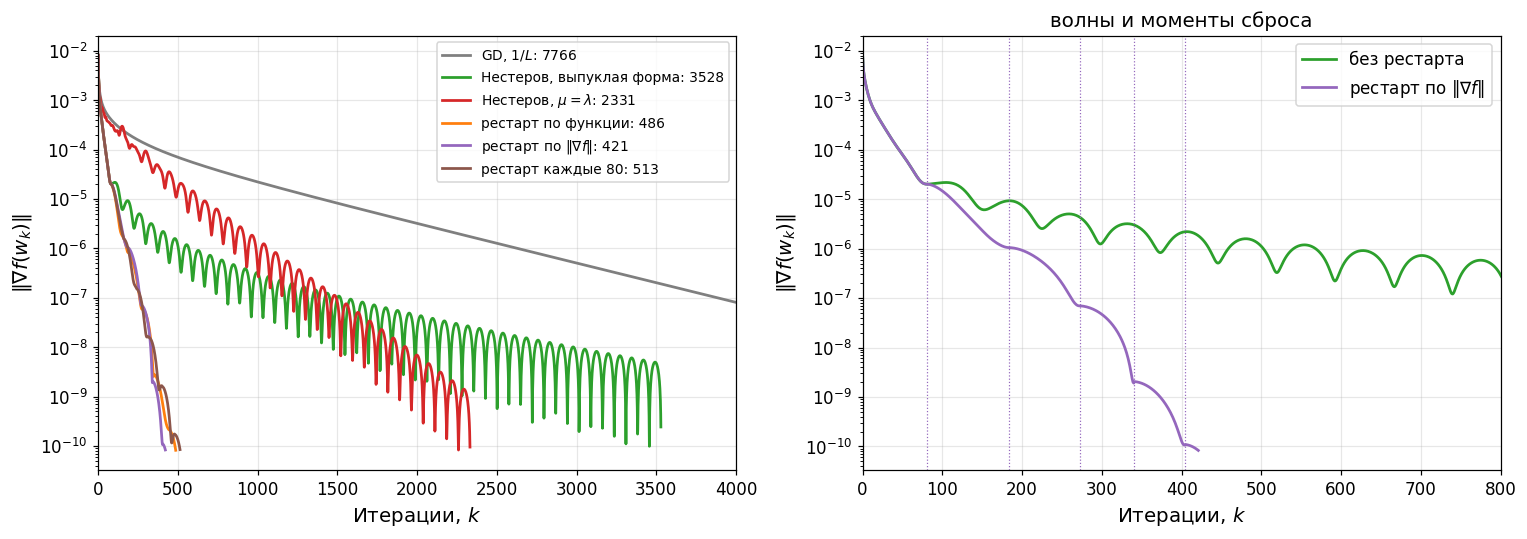

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cols = ["C7", "C2", "C3", "C1", "C4", "C5"]
for m, c in zip(ms_lr, cols):
    axes[0].semilogy([np.linalg.norm(g_lr(p)) for p, _ in m.history], color=c,
                     label=f"{m.name}: {iters(m)}")
axes[0].set_xlim(0, 4000); axes[0].set_xlabel("Итерации, $k$")
axes[0].set_ylabel(r"$\|\nabla f(w_k)\|$"); axes[0].grid(alpha=.3); axes[0].legend(fontsize=9)

mc, mr = ms_lr[1], ms_lr[4]
axes[1].semilogy([np.linalg.norm(g_lr(p)) for p, _ in mc.history], color="C2",
                 label="без рестарта")
axes[1].semilogy([np.linalg.norm(g_lr(p)) for p, _ in mr.history], color="C4",
                 label=r"рестарт по $\|\nabla f\|$")
for r in mr.restarts:
    axes[1].axvline(r, color="C4", lw=.8, ls=":")
axes[1].set_xlim(0, 800); axes[1].set_xlabel("Итерации, $k$")
axes[1].set_ylabel(r"$\|\nabla f(w_k)\|$"); axes[1].set_title("волны и моменты сброса")
axes[1].grid(alpha=.3); axes[1].legend()
plt.tight_layout(); plt.show()

Волны видны невооружённым глазом: у выпуклой формы норма градиента осциллирует на всём протяжении, с периодом, который растёт по мере приближения к решению. Пунктиром отмечены моменты сброса у адаптивного правила — каждый приходится на начало очередной волны, и после него кривая снова идёт вниз круто.

### 8.1. Насколько важно угадать период

У фиксированного рестарта есть параметр $K$. Проверим, насколько чувствителен к нему результат.

K =    5:    5173 итераций
K =   10:    3640 итераций
K =   20:    2264 итераций
K =   40:    1231 итераций
K =   80:     513 итераций
K =  160:     607 итераций
K =  320:     876 итераций
K =  640:    1367 итераций


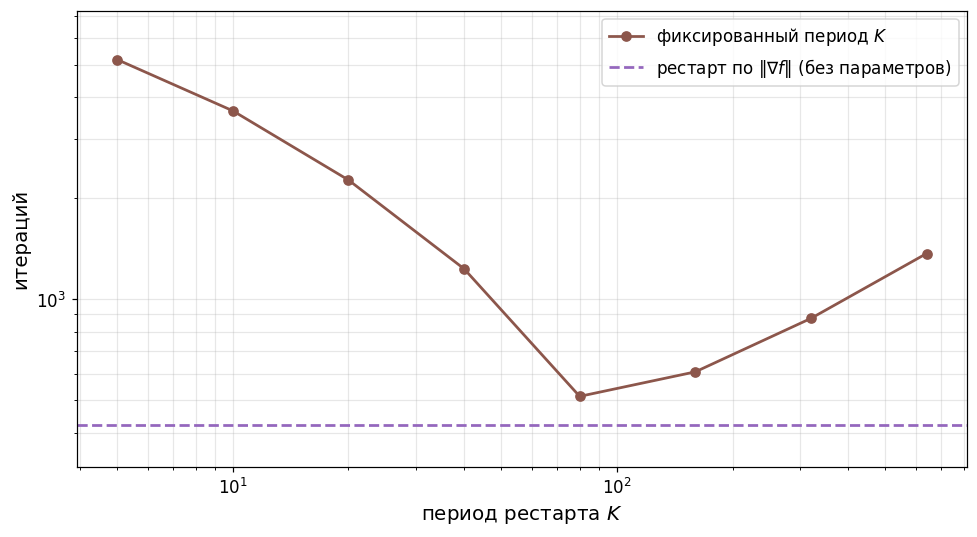

In [ ]:
periods = [5, 10, 20, 40, 80, 160, 320, 640]
it_per = []
for K in periods:
    m = Nesterov(L_lr, restart="fixed", period=K)
    m.solve(w0, f_lr, g_lr, tol=tol_lr, max_iter=100000)
    it_per.append(iters(m))
    print(f"K = {K:4d}:  {iters(m):6d} итераций")

m_grad = ms_lr[4]

fig, ax = plt.subplots(figsize=(9, 5))
ax.loglog(periods, it_per, "o-", color="C5", label="фиксированный период $K$")
ax.axhline(iters(m_grad), color="C4", ls="--", label=r"рестарт по $\|\nabla f\|$ (без параметров)")
ax.set_ylim(0.75 * min(iters(m_grad), min(it_per)), 1.4 * max(it_per))
ax.set_xlabel("период рестарта $K$"); ax.set_ylabel("итераций")
ax.grid(alpha=.3, which="both"); ax.legend()
plt.tight_layout(); plt.show()

Кривая имеет минимум около $K = 80$, и промахи несимметричны: при $K = 10$ (в восемь раз меньше) нужно $3640$ итераций, то есть в семь раз больше минимума, а при $K = 640$ (в восемь раз больше) — $1367$, всего в два с половиной раза. Слишком частый рестарт вредит сильнее, чем слишком редкий: он просто не даёт методу разогнаться.

Пунктирная горизонталь — адаптивное правило. Оно не просто попадает в окрестность минимума, а оказывается ниже лучшего $K$ из перебранной сетки: $421$ итерация против $513$ при $K = 80$. Причина в том, что фиксированный период одинаков на всём ходу работы, а нужная длина цикла меняется по мере приближения к решению — это видно по правому графику выше, где волны становятся всё длиннее. Адаптивное правило подстраивается, и настраивать в нём нечего.

---
# Часть IV. Адаптивная оценка $\mu$

## 9. Зачем нужна именно $\mu$ и что её заменяет

Рестарт решает задачу неявно: он не оценивает $\mu$, а просто не даёт инерции разогнаться сверх меры. Но можно действовать и прямо — оценивать $\mu$ по ходу работы и подставлять оценку в сильно выпуклую форму.

Сначала о том, что вообще требуется. Линейная скорость ускоренного метода не нуждается в сильной выпуклости в полном объёме. Достаточно **условия квадратичного роста**:
$$f(x) - f^* \ \ge\ \frac{\mu}{2}\,\mathrm{dist}(x, X^*)^2 \qquad \text{для всех } x \text{ вблизи } X^*,$$
где $X^*$ — множество решений. Это условие слабее сильной выпуклости: оно ничего не требует от поведения $f$ вдали от решения и допускает неединственный минимум. Для выпуклых функций с липшицевым градиентом квадратичный рост эквивалентен оценке ошибки
$$\|\nabla f(x)\| \ \ge\ \mu\,\mathrm{dist}(x, X^*),$$
и именно в такой форме его удобно превращать в вычислимую оценку: $\mu$ — это отношение нормы градиента к расстоянию до решения, то есть то, насколько быстро градиент растёт при удалении от минимума.

*Замечание.* Квадратичный рост функции — это в точности гладкость сопряжённой к ней функции (у сопряжённой липшицев градиент). Так что $\mu$ и $L$ меняются ролями при переходе к сопряжённой задаче. Сопряжённые функции мы здесь не вводим и этим фактом не пользуемся, но он объясняет, почему оценка $\mu$ технически устроена так же, как привычная оценка $L$ по секущей.

## 10. Оценка по секущей и алгоритм NAG-free

Расстояние до решения неизвестно, но то же отношение можно взять не до решения, а между двумя соседними точками траектории. Для $\mu$-сильно выпуклой функции с $L$-липшицевым градиентом при любых $x, y$
$$\mu\,\|x - y\| \ \le\ \|\nabla f(x) - \nabla f(y)\| \ \le\ L\,\|x - y\| .$$

Значит, отношение приращения иксов к приращению градиента
$$\frac{\|x_{t+1} - x_t\|}{\|\nabla f(x_{t+1}) - \nabla f(x_t)\|} \ \in\ \left[\frac1L,\ \frac1\mu\right]$$
всегда зажато между $1/L$ и $1/\mu$, а обратная к нему величина
$$c_{t+1} = \frac{\|\nabla f(x_{t+1}) - \nabla f(x_t)\|}{\|x_{t+1} - x_t\|} \ \in\ [\mu,\ L]$$
— это кривизна вдоль пройденного отрезка, то есть **оценка $\mu$ сверху**. Одно измерение ничего не даёт: вдоль крутого направления оно покажет что-то близкое к $L$. Но траектория ускоренного метода со временем выстраивается вдоль самых пологих направлений, поэтому бегущий минимум $c_{t+1}$ сходится к искомой величине сверху. Та же конструкция с бегущим максимумом даёт привычную оценку $L$ снизу.

Ключевая деталь: если брать $c_{t+1}$ именно по точкам $x_t$, в которых метод и так вычисляет градиент, оценка достаётся **бесплатно**. Никаких дополнительных обращений к оракулу, только один лишний хранимый вектор.

На этом построен алгоритм **NAG-free** (Cavalcanti, Lessard, Wilson, 2025, [arXiv:2506.13033](https://arxiv.org/abs/2506.13033)) — это в точности ускоренный метод Нестерова, в котором $\mu$ заменена на текущую оценку $m_t$:

$$
\begin{aligned}
&\text{шаг по градиенту:} && y_{t+1} = x_t - \tfrac1{\bar L}\,\nabla f(x_t), \\[2pt]
&\text{экстраполяция:}    && x_{t+1} = y_{t+1} + \beta_t\,(y_{t+1} - y_t), \qquad \beta_t = \frac{\sqrt{\bar L} - \sqrt{m_t}}{\sqrt{\bar L} + \sqrt{m_t}}, \\[2pt]
&\text{кривизна:}         && c_{t+1} = \frac{\|\nabla f(x_{t+1}) - \nabla f(x_t)\|}{\|x_{t+1} - x_t\|}, \\[2pt]
&\text{обновление оценки:}&& m_{t+1} = \min\{m_t,\ c_{t+1}\}.
\end{aligned}
$$

Начальное значение $m_0$ берётся по той же формуле в паре из $x_0$ и близкой к ней случайной точки, а $\bar L \ge L$ — единственный параметр, который нужно знать.

Несколько замечаний к схеме.

* Коэффициент $\beta_t$ непрерывно интерполирует между двумя крайностями: при $m_t = \bar L$ получается $\beta_t = 0$, то есть обычный градиентный спуск, при $m_t = \mu$ — настоящий ускоренный метод. Оценка стартует с большого значения и ползёт вниз, то есть метод начинает как градиентный спуск и постепенно включает ускорение по мере того, как убеждается в пологости задачи. Поэтому он не может оказаться хуже градиентного спуска: оценка $m_t$ никогда не опускается ниже $\mu$ по построению, и завышения $\beta_t$ — опасной стороны — здесь не бывает.
* Рестарты не нужны. В этом главное отличие от части III: там мы боролись с последствиями неправильного $\beta$, здесь $\beta$ сразу берётся правильным.
* В анализе используется вариант с гарантированным геометрическим убыванием оценки: при $c_{t+1} < m_t$ полагается $m_{t+1} = \min\{c_{t+1},\, m_t/\gamma\}$ с $\gamma \le 2$. На практике он сходится чуть быстрее, потому что не застревает на завышенной оценке; ниже приведены оба варианта.
* Известные гарантии: если $L$ подбирать backtracking'ом, метод глобально сходится не медленнее градиентного спуска; при известной верхней оценке $\bar L \ge L$ и локально гладком гессиане он локально ускоряется. Глобальной гарантии ускорения нет — в этом он не отличается от рестартов.
* Оценивать по той же секущей можно и $L$: бегущий максимум $L_{t+1} = \max\{L_t,\, c_{t+1}\}$. В статье это сделано в варианте NAG-free-back вместе с backtracking по ослабленной лемме о спуске; мы берём $\bar L$ известной и этот вариант не реализуем.

In [ ]:
class NAGFree(Method):
    # Отличие от класса Nesterov только в том, что beta_t берётся по текущей
    # оценке m_t, а сама оценка обновляется бегущим минимумом секущей кривизны.
    # Дополнительных вызовов оракула нет: g и g_new всё равно нужны методу.
    def __init__(self, L, gamma=None, seed=0, name=None):
        super().__init__(name)
        self.L, self.gamma, self.seed = L, gamma, seed
        self.m_hist = []
    def solve(self, x0, f, gradf, tol=1e-8, max_iter=10000):
        L = self.L
        rng = np.random.default_rng(self.seed)
        x = x0.copy()
        y = x0 + 1e-6 * rng.random(x0.shape)          # пробная точка для m_0
        m = np.linalg.norm(gradf(x) - gradf(y)) / np.linalg.norm(x - y)
        m = min(max(m, L * 1e-14), L)
        self.history = [(x.copy(), time.time())]; self.m_hist = []
        g = gradf(x); gn = np.linalg.norm(g)
        for t in range(max_iter):
            if gn <= tol:
                break
            y_new = x - g / L
            beta = (np.sqrt(L) - np.sqrt(m)) / (np.sqrt(L) + np.sqrt(m))
            x_new = y_new + beta * (y_new - y)
            g_new = gradf(x_new); gn_new = np.linalg.norm(g_new)
            dx = np.linalg.norm(x_new - x)
            if dx > 0:
                c = np.linalg.norm(g_new - g) / dx      # секущая кривизна, c in [m, L]
                if c < m:
                    m = c if self.gamma is None else min(c, m / self.gamma)
                    m = max(m, L * 1e-14)
            x, y, g, gn = x_new, y_new, g_new, gn_new
            self.m_hist.append(m)
            self.history.append((y.copy(), time.time()))
        return y

## 11. NAG-free на той же задаче

Запустим NAG-free на уже построенной задаче и сравним с лучшим из рестартов.

In [ ]:
ms_nf = [Nesterov(L_lr, "sc", mu=lam,      name=r"Нестеров, $\mu = \lambda$"),
         Nesterov(L_lr, restart="grad",    name=r"рестарт по $\|\nabla f\|$"),
         NAGFree(L_lr,                     name="NAG-free"),
         NAGFree(L_lr, gamma=2.0,          name=r"NAG-free, $\gamma = 2$")]
for m in ms_nf:
    m.solve(w0, f_lr, g_lr, tol=tol_lr, max_iter=300000)
    extra = f"   m_hat = {m.m_hist[-1]:.3e}" if getattr(m, "m_hist", None) else ""
    print(f"{m.name:28s} {iters(m):7d} итераций{extra}")

# истинная кривизна в найденном решении
w_star = ms_nf[2].history[-1][0]
p = 1 / (1 + np.exp(-(Ay @ w_star)))
H = (Ay * (p * (1 - p))[:, None]).T @ Ay / m_lr + lam * np.eye(n_lr)
ev = np.linalg.eigvalsh(H)
print(f"\nв решении: mu = {ev[0]:.3e} (это {ev[0]/lam:.0f} x lambda),  "
      f"L = {ev[-1]:.3e},  фактическое kappa = {ev[-1]/ev[0]:.0f}")

Нестеров, $\mu = \lambda$       2331 итераций
рестарт по $\|\nabla f\|$        421 итераций
NAG-free                         435 итераций   m_hat = 9.154e-07
NAG-free, $\gamma = 2$           396 итераций   m_hat = 6.294e-07

в решении: mu = 9.153e-07 (это 92 x lambda),  L = 2.864e-04,  фактическое kappa = 313


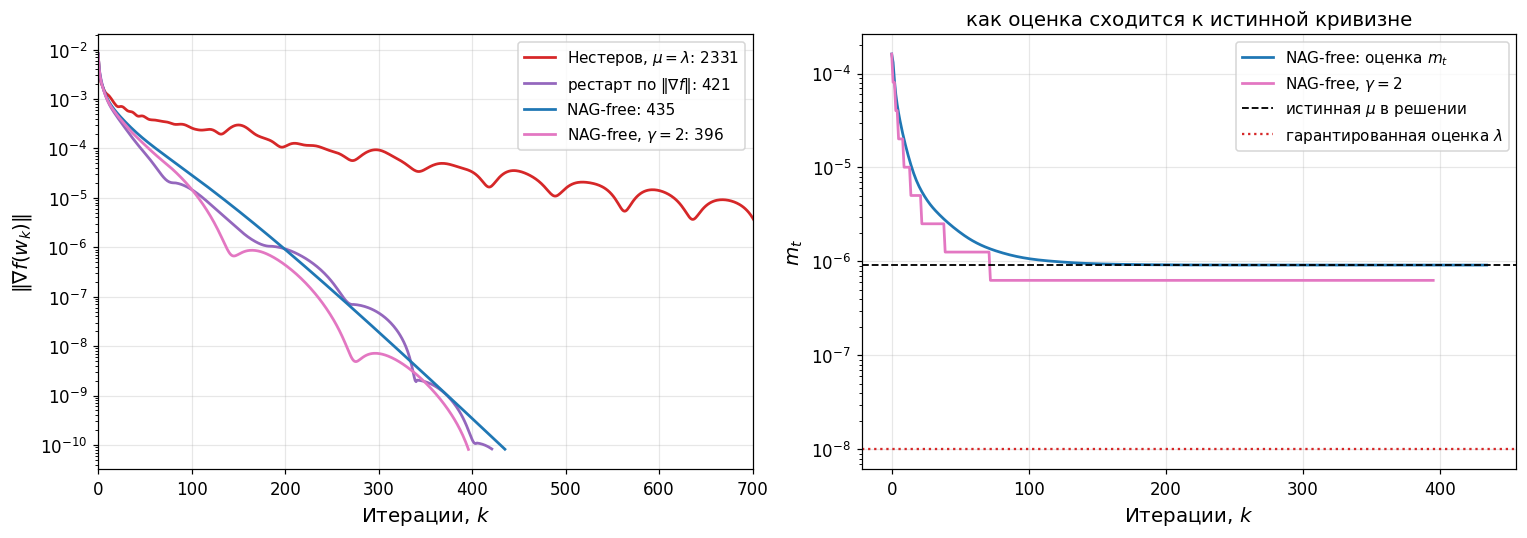

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for m, c in zip(ms_nf, ["C3", "C4", "C0", "C6"]):
    axes[0].semilogy([np.linalg.norm(g_lr(p_)) for p_, _ in m.history], color=c,
                     label=f"{m.name}: {iters(m)}")
axes[0].set_xlim(0, 700); axes[0].set_xlabel("Итерации, $k$")
axes[0].set_ylabel(r"$\|\nabla f(w_k)\|$"); axes[0].grid(alpha=.3); axes[0].legend(fontsize=10)

axes[1].semilogy(ms_nf[2].m_hist, color="C0", label=r"NAG-free: оценка $m_t$")
axes[1].semilogy(ms_nf[3].m_hist, color="C6", label=r"NAG-free, $\gamma=2$")
axes[1].axhline(ev[0], color="k", ls="--", lw=1.2, label=r"истинная $\mu$ в решении")
axes[1].axhline(lam, color="C3", ls=":", lw=1.5, label=r"гарантированная оценка $\lambda$")
axes[1].set_xlabel("Итерации, $k$"); axes[1].set_ylabel(r"$m_t$")
axes[1].set_title("как оценка сходится к истинной кривизне")
axes[1].grid(alpha=.3); axes[1].legend(fontsize=10)
plt.tight_layout(); plt.show()

Гарантированная оценка $\mu = \lambda$ занижена примерно в девяносто раз, и метод с ней работает в пять раз медленнее: он честно разгоняется под $\kappa = 5\cdot10^4$, тогда как настоящее число обусловленности около $300$. NAG-free выходит на истинное значение $\mu$ за сотню итераций и дальше держится на нём — на правом графике синяя кривая ложится на чёрный пунктир.

Вариант с $\gamma = 2$ спускается ступеньками и останавливается немного **ниже** истинной $\mu$ (на $6.3\cdot10^{-7}$ против $9.2\cdot10^{-7}$): деление на $\gamma$ может проскочить правильное значение. Это безопасная сторона — заниженная оценка даёт меньший $\beta_t$, то есть недоускорение, а не расходимость, — и на скорости это не сказалось.

Разница между двумя подходами в том, что именно они делают с инерцией. Рестарт ничего не знает о задаче и просто сбивает разгон, когда тот явно избыточен; это реакция постфактум, по одной итерации на каждую волну. NAG-free вместо этого сразу подбирает правильный коэффициент инерции и волн не допускает. Стоит это одного дополнительного хранимого вектора и нуля дополнительных обращений к оракулу: оба градиента в формуле для $c_{t+1}$ метод вычисляет и так.

### 11.1. Что происходит при уменьшении регуляризации

Коэффициент $\lambda$ задаёт гарантированное $\kappa = L/\lambda$, но настоящее число обусловленности вблизи решения выходит на плато: вклад данных в кривизну от $\lambda$ почти не зависит. Проследим, как расходятся эти две величины и что при этом происходит с методами.

lambda = 1e-04:  kappa гарант.  6.0e+00,  kappa факт.      5  |  mu=lam    32   рестарт    53   NAG-free    38   NAG-free(g=2)    40
lambda = 1e-05:  kappa гарант.  5.1e+01,  kappa факт.     29  |  mu=lam   103   рестарт   133   NAG-free   117   NAG-free(g=2)   108
lambda = 1e-06:  kappa гарант.  5.0e+02,  kappa факт.    114  |  mu=lam   327   рестарт   326   NAG-free   259   NAG-free(g=2)   229
lambda = 1e-07:  kappa гарант.  5.0e+03,  kappa факт.    259  |  mu=lam   931   рестарт   451   NAG-free   395   NAG-free(g=2)   417
lambda = 1e-08:  kappa гарант.  5.0e+04,  kappa факт.    313  |  mu=lam  2331   рестарт   421   NAG-free   435   NAG-free(g=2)   396


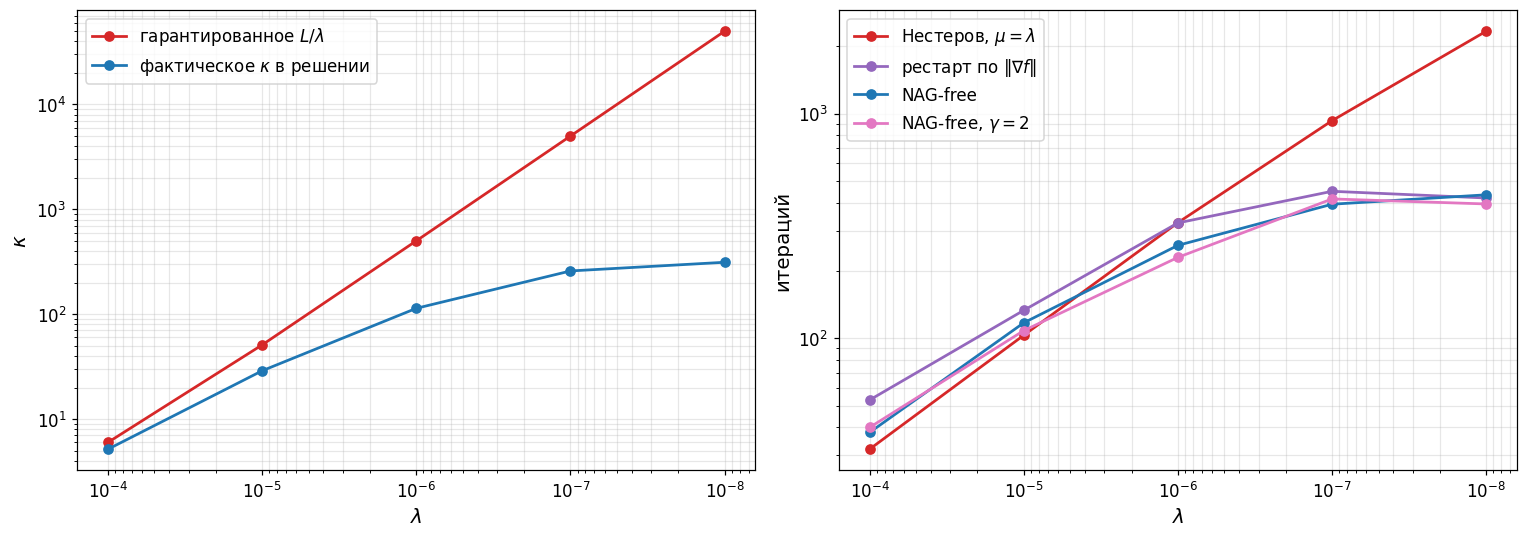

In [ ]:
lams = [1e-4, 1e-5, 1e-6, 1e-7, 1e-8]
res = {k: [] for k in [r"Нестеров, $\mu=\lambda$", r"рестарт по $\|\nabla f\|$",
                       "NAG-free", r"NAG-free, $\gamma=2$"]}
kap_gar, kap_fact = [], []

for lm in lams:
    f_ = lambda w, lm=lm: np.mean(np.logaddexp(0, -(Ay @ w))) + lm / 2 * w @ w
    def g_(w, lm=lm):
        z = Ay @ w
        return Ay.T @ (-1 / (1 + np.exp(z))) / m_lr + lm * w
    L_ = lm + np.linalg.norm(Adat, 2)**2 / (4 * m_lr)
    tol_ = 1e-8 * np.linalg.norm(g_(w0))
    ms_ = [Nesterov(L_, "sc", mu=lm), Nesterov(L_, restart="grad"),
           NAGFree(L_), NAGFree(L_, gamma=2.0)]
    for key, m in zip(res, ms_):
        m.solve(w0, f_, g_, tol=tol_, max_iter=300000)
        res[key].append(iters(m))
    ws = ms_[2].history[-1][0]
    p_ = 1 / (1 + np.exp(-(Ay @ ws)))
    H_ = (Ay * (p_ * (1 - p_))[:, None]).T @ Ay / m_lr + lm * np.eye(n_lr)
    e_ = np.linalg.eigvalsh(H_)
    kap_gar.append(L_ / lm); kap_fact.append(e_[-1] / e_[0])
    v = [res[k][-1] for k in res]
    print(f"lambda = {lm:.0e}:  kappa гарант. {L_/lm:8.1e},  kappa факт. {e_[-1]/e_[0]:6.0f}  |  "
          f"mu=lam {v[0]:5d}   рестарт {v[1]:5d}   NAG-free {v[2]:5d}   NAG-free(g=2) {v[3]:5d}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].loglog(lams, kap_gar, "o-", color="C3", label=r"гарантированное $L/\lambda$")
axes[0].loglog(lams, kap_fact, "o-", color="C0", label=r"фактическое $\kappa$ в решении")
axes[0].invert_xaxis(); axes[0].set_xlabel(r"$\lambda$"); axes[0].set_ylabel(r"$\kappa$")
axes[0].grid(alpha=.3, which="both"); axes[0].legend()

for (k, v), c in zip(res.items(), ["C3", "C4", "C0", "C6"]):
    axes[1].loglog(lams, v, "o-", color=c, label=k)
axes[1].invert_xaxis(); axes[1].set_xlabel(r"$\lambda$"); axes[1].set_ylabel("итераций")
axes[1].grid(alpha=.3, which="both"); axes[1].legend()
plt.tight_layout(); plt.show()

Левый график показывает расхождение: гарантированное $\kappa$ растёт как $1/\lambda$, фактическое выходит на плато около $300$. Правый — к чему это приводит. Метод с $\mu = \lambda$ следует за гарантированной оценкой и теряет скорость в семьдесят раз, а рестарт и NAG-free следуют за фактической и к $\lambda = 10^{-8}$ выходят на плато. При $\lambda = 10^{-4}$, где оценка $\mu = \lambda$ ещё почти точна (фактическое $\kappa = 5$ против гарантированного $6$), она даже лучше всех: $32$ итерации против $38$ у NAG-free и $53$ у рестарта. Расхождение появляется ровно там, где гарантированная оценка перестаёт быть правдой, — начиная с $\lambda = 10^{-6}$.

## 12. Сравнение с нелинейным CG

На той же задаче запустим нелинейный метод сопряжённых градиентов. Сравнивать по итерациям здесь мало: линейный поиск по Вольфу требует нескольких вычислений $f$ и $\nabla f$ за итерацию, тогда как ускоренным методам хватает одного градиента.

In [ ]:
def run_counted(method, x0, f, gradf, tol, max_iter):
    orc = Oracle(f, gradf)
    t0 = time.time()
    method.solve(x0, orc.f, orc.gradf, tol=tol, max_iter=max_iter)
    return iters(method), orc.nf, orc.ng, time.time() - t0

ms_cmp = [NonlinearCG("FR",                    name="CG Флетчера--Ривса"),
          NonlinearCG("PR",                    name="CG Полака--Рибьера"),
          NonlinearCG("FR", restart=50,        name="CG ФР, рестарт каждые 50"),
          Nesterov(L_lr, restart="grad",       name=r"Нестеров + рестарт по $\|\nabla f\|$"),
          NAGFree(L_lr, gamma=2.0,             name=r"NAG-free, $\gamma = 2$")]
print(f"{'метод':34s} {'итераций':>9} {'вызовов f':>11} {'вызовов grad':>13} {'время, с':>10}")
for m in ms_cmp:
    it, nf, ng, dt = run_counted(m, w0, f_lr, g_lr, tol_lr, 20000)
    print(f"{m.name:34s} {it:9d} {nf:11d} {ng:13d} {dt:10.2f}")

метод                               итераций   вызовов f  вызовов grad   время, с
CG Флетчера--Ривса                       915       16611         13472       2.21
CG Полака--Рибьера                      1851       44048         34521       5.68
CG ФР, рестарт каждые 50                 570       14816         10687       1.88
Нестеров + рестарт по $\|\nabla f\|$       421           0           422       0.03
NAG-free, $\gamma = 2$                   396           0           399       0.03


Нелинейный CG доходит до той же точности, но платит за каждую итерацию линейным поиском, и по суммарному числу обращений к оракулу проигрывает примерно на порядок. Это общее правило: на квадратичных задачах сопряжённые градиенты — лучший выбор, потому что шаг там считается аналитически и метод конечен; на неквадратичных преимущество переходит к ускоренным методам.

---
## Итоги

| метод | что нужно знать | итераций | немонотонность |
|---|---|---|---|
| GD, $\alpha = 1/L$ | $L$ | $O(\kappa\log\frac1\varepsilon)$ | нет |
| тяжёлый шарик | $L$, $\mu$ | $O(\sqrt{\kappa}\log\frac1\varepsilon)$ | да; на неквадратичных задачах гарантий нет |
| Нестеров, выпуклая форма | $L$ | $O(1/k^2)$, линейной скорости нет | да, волнами |
| Нестеров, сильно выпуклая форма | $L$, $\mu$ | $O(\sqrt{\kappa}\log\frac1\varepsilon)$ | да |
| Нестеров + рестарт | $L$ | как с известным $\mu$ | сбивается рестартом |
| NAG-free | $\bar L \ge L$ | как с известным $\mu$ | нет волн: $\beta_t$ сразу верный |
| CG (квадратичная задача) | ничего | $\le n$ (в точной арифметике) | да |
| нелинейный CG | ничего | дорогая итерация из-за линейного поиска | да |

* Ускорение меняет не длину шага, а направление: инерция превращает $\kappa$ в $\sqrt{\kappa}$.
* Цена ускорения — немонотонность и зависимость параметров от $\mu$.
* Рестарт снимает обе проблемы сразу и не требует ни одной настраиваемой константы. Правило по норме градиента вдобавок не требует вычислять $f$.
* $\mu$ можно оценивать прямо по траектории: бегущий минимум отношения приращения градиента к приращению аргумента. Мотивирует это условие квадратичного роста, по которому $\mu$ — отношение нормы градиента к расстоянию до решения. Если брать отношение по точкам, где метод и так считает градиент, оценка достаётся бесплатно; на этом построен NAG-free.
* Оценка $\mu$ получается сверху и монотонно убывает, поэтому $\beta_t$ никогда не завышен: метод стартует как градиентный спуск и включает ускорение по мере того, как убеждается в пологости задачи. Рестарты при этом не нужны.
* На квадратичных задачах сопряжённые градиенты обыгрывают всё остальное: шаг считается аналитически, настраиваемых параметров нет, а число итераций ограничено размерностью.